  Obtaining dependency information for mlxtend from https://files.pythonhosted.org/packages/73/da/d5d77a9a7a135c948dbf8d3b873655b105a152d69e590150c83d23c3d070/mlxtend-0.23.0-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --- ------------------------------------ 0.1/1.4 MB 2.7 MB/s eta 0:00:01
   -------------- ------------------------- 0.5/1.4 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------  1.4/1.4 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 9.2 MB/s eta 0:00:00


C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\base.py:443: UserWarning: X has feature names, but FunctionTransformer was fitted without feature names
  warnings.warn(
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:292: RuntimeWarning: divide by zero encountered in log1p
  return func(X, **(kw_args if kw_args else {}))
C:\Users\Anita Taylor\anaconda3\Lib\site-packages\sklearn\preprocessing\_function_transformer.py:292: RuntimeWarning: invalid value encountered in log1p
  return func(X, **(kw_args if kw_args else {}))


                            OLS Regression Results                            
Dep. Variable:                   As-T   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.435e+24
Date:                Wed, 29 Nov 2023   Prob (F-statistic):               0.00
Time:                        18:52:50   Log-Likelihood:                 27887.
No. Observations:                 985   AIC:                        -5.573e+04
Df Residuals:                     963   BIC:                        -5.562e+04
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  1.56e-13 

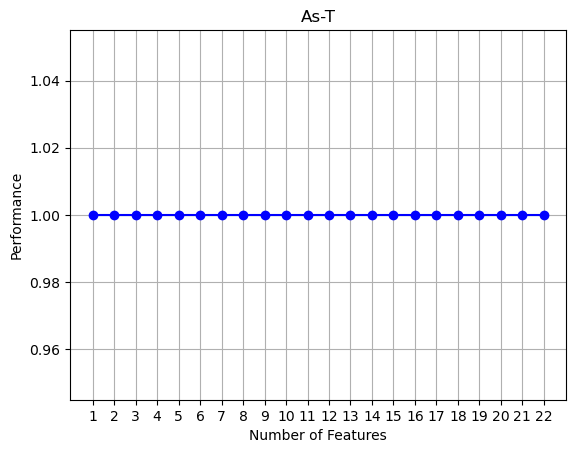

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33468\2201723005.py:98: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ksa_res.resid, fit=stats.norm, ax=ax[0, 0])
C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_33468\2201723005.py:105: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


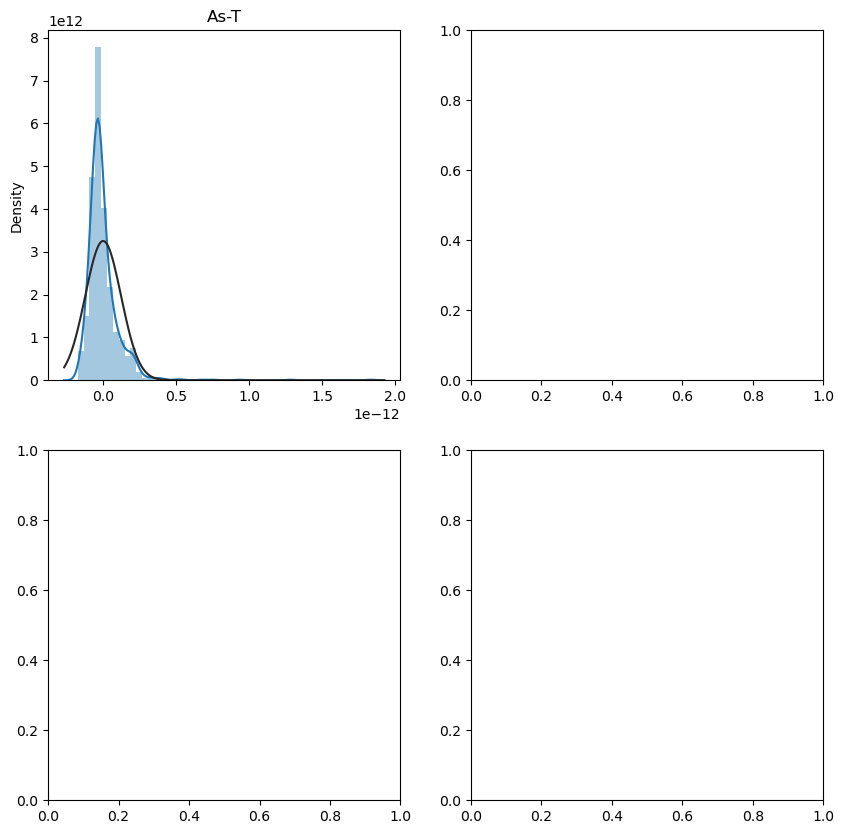

In [1]:
!pip install umap-learn
!pip install mlxtend

import statsmodels.api as sm
import numpy as np
from sklearn.datasets import load_digits
from umap import UMAP
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LinearRegression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import statsmodels.formula.api as smf
from scipy import stats

# Load your data
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()
Datat['FD'] = Datat['PRECIPITATION'] - Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP'] - Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP'] - Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'

Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
Datat = Datat.dropna()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID', 'Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number', 'Well Tag Number', 'Cd-T']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

DropDF1b = ['Aquifer Subtype', 'Alkalinity Total 4.5', 'Hardness Total (T)', 'Precip_Climatology', 'Tn_Climatology', 'Tx_Climatology', 'Residue Filterable 1.0u']
Datat = Datat.drop(DropDF1b, axis=1, errors='ignore')
Datawithtime = Datat.copy()

DropDF1c = ['DATE', 'LONGITUDE', 'LATITUTE', 'year_month', 'OBSWell']
Datat = Datat.drop(DropDF1c, axis=1, errors='ignore')

# Scaling
transformer = FunctionTransformer(np.log1p, validate=True)
Datat_notypes = Datat.select_dtypes(exclude=['object'])  # Select only numerical columns
dftrans = transformer.transform(Datat_notypes)

# Convert 'Aquifer Group' column to numerical values
Datat['Aquifer Group'] = pd.to_numeric(Datat['Aquifer Group'], errors='coerce')

# Drop rows with NaN values in 'Aquifer Group' column
Datat = Datat.dropna(subset=['Aquifer Group'])

# Regression analysis
Ya = Datat['As-T']
Xa = Datat[['OBSWELL', 'As-T', 'Ca-T', 'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T',
       'P--T', 'Pb-T', 'Specific Conductance', 'Sulfat:D', 'pH', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group']]
Xa = sm.add_constant(Xa)

# Ordinary Least Squares (OLS) regression for As-T
ksa = sm.OLS(Ya, Xa)
ksa_res = ksa.fit()
print(ksa_res.summary())

# Similar regression analysis for other target variables (Mn-T, Pb-T, U--T)

# Feature selection using Sequential Feature Selector (SFS)
mod = LinearRegression()
sfs = SFS(mod,
          k_features='best',
          forward=False,
          floating=False,
          scoring='r2',
          cv=30)

sfs = sfs.fit(Xa, Ya)
print(pd.DataFrame.from_dict(sfs.get_metric_dict(confidence_interval=0.95)).T)

plot_sfs(sfs.get_metric_dict(), kind='std_err')
plt.grid()
plt.title("As-T")
plt.show()

# Similar feature selection for other target variables

# Residual analysis
fig, ax = plt.subplots(2, 2, figsize=(10, 10))

sns.distplot(ksa_res.resid, fit=stats.norm, ax=ax[0, 0])
# Similar plots for other target variables

# Add labels and save
ax[0, 0].set_title('As-T')
# Similar labels for other target variables

fig.show()

In [20]:
print(Datat.dtypes)

OBSWELL                   int64
As-T                    float64
Ca-T                    float64
Chlrid:D                float64
Fe-T                    float64
Mn-T                    float64
N.Kjel:T                float64
P--T                    float64
Pb-T                    float64
Specific Conductance    float64
Sulfat:D                float64
pH                      float64
K--T                    float64
U--T                    float64
PRECIPITATION           float64
MIN_TEMP                float64
MAX_TEMP                float64
FD                      float64
HW                      float64
MT                      float64
Aquifer Group            object
dtype: object
